In [1]:
from keras.datasets import california_housing

(train_data, train_targets), (test_data, test_targets) = california_housing.load_data(
    version="small"
)

print(f"{train_data.shape=}")
print(f"{train_targets.shape=}")
print(f"{test_data.shape=}")
print(f"{test_targets.shape=}")

train_data.shape=(480, 8)
train_targets.shape=(480,)
test_data.shape=(120, 8)
test_targets.shape=(120,)


In [2]:
train_data_mean = train_data.mean(axis=0)
train_data_std = train_data.std(axis=0)
dollar_value_scale = 100_000

x_train = (train_data - train_data_mean) / train_data_std
y_train = train_targets / dollar_value_scale
x_test = (test_data - train_data_mean) / train_data_std
y_test = test_targets / dollar_value_scale

print(f"{train_data.shape=}")
print(f"{train_targets.shape=}")
print(f"{test_data.shape=}")
print(f"{test_targets.shape=}")

train_data.shape=(480, 8)
train_targets.shape=(480,)
test_data.shape=(120, 8)
test_targets.shape=(120,)


In [3]:
import keras


def get_model():
    model = keras.Sequential(
        [
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dense(1),
        ]
    )

    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mean_absolute_error"],
    )

    return model

In [4]:
import numpy as np

k = 4
num_val_samples = len(x_train) // k
num_epochs = 200
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i + 1}")

    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]

    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )

    model = get_model()

    history = model.fit(
        fold_x_train,
        fold_y_train,
        validation_data=(fold_x_val, fold_y_val),
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )

    mae_history = history.history["val_mean_absolute_error"]
    all_mae_histories.append(mae_history)

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


In [5]:
average_mae_history = [
    np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)
]

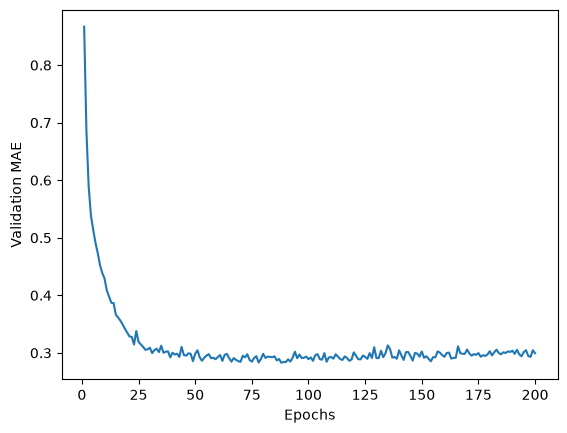

In [6]:
import matplotlib.pyplot as plt

epochs = range(1, len(average_mae_history) + 1)
plt.plot(epochs, average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

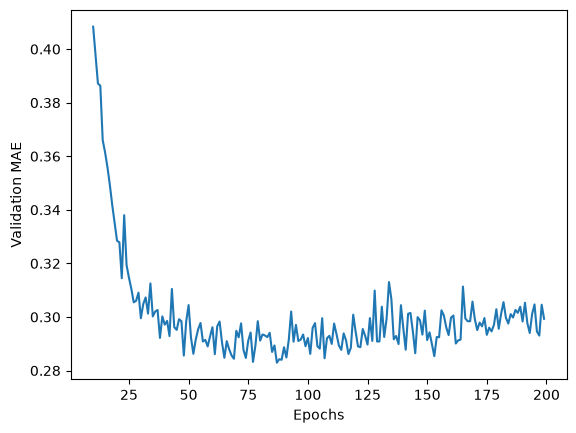

In [7]:
truncated_mae_history = average_mae_history[10:]
epochs = range(10, len(truncated_mae_history) + 10)
plt.plot(epochs, truncated_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [8]:
# Gets a fresh, compiled model
model = get_model()
# Trains it on the entirety of the data
model.fit(x_train, y_train, epochs=130, batch_size=16, verbose=0)
test_mean_squared_error, test_mean_absolute_error = model.evaluate(
    x_test, y_test
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2982 - mean_absolute_error: 0.3232 


In [9]:
round(test_mean_absolute_error, 3)

0.323

In [10]:
predictions = model.predict(x_test)
predictions[0]

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


array([2.4275882], dtype=float32)